In [29]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.append(str(project_root))

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.adx_connection import run_kql

cleaned_data = pd.read_parquet(r"C:\Users\SUPRA\Downloads\Financial Fabric Project\Data\nifty50_cleaned.parquet")
cleaned_data.head()

,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,_Deliverble,Turnover_corrected
0,2007-11-27 00:00:00+00:00,MUNDRAPORT,EQ,440.0,770.0,1050.0,770.0,959.0,962.9,984.72,27294366,2687719053785000.0,<NA>,9859619.0,0.3612,26877190537.849998
1,2007-11-28 00:00:00+00:00,MUNDRAPORT,EQ,962.9,984.0,990.0,874.0,885.0,893.9,941.38,4581338,431276530165000.0,<NA>,1453278.0,0.3172,4312765301.65
2,2007-11-29 00:00:00+00:00,MUNDRAPORT,EQ,893.9,909.0,914.75,841.0,887.0,884.2,888.09,5124121,455065846265000.0,<NA>,1069678.0,0.2088,4550658462.65
3,2007-11-30 00:00:00+00:00,MUNDRAPORT,EQ,884.2,890.0,958.0,890.0,929.0,921.55,929.17,4609762,428325662830000.0,<NA>,1260913.0,0.2735,4283256628.3
4,2007-12-03 00:00:00+00:00,MUNDRAPORT,EQ,921.55,939.75,995.0,922.0,980.0,969.3,965.65,2977470,287519974300000.0,<NA>,816123.0,0.2741,2875199743.0


In [4]:
print(cleaned_data.shape)

(235192, 16)


## 1. **Trend Analysis: Cross-Sector Price Movement (2000-2021)**
Comparing closing price trends across RELIANCE, HDFCBANK, TCS, and INFY, spanning energy, banking, and IT, to spot sector-driven differences.

In [5]:
trend_data = run_kql("""
NIFTY50_all
| where Symbol in ("RELIANCE", "TCS", "HDFCBANK", "INFY")
| summarize avg(Close) by Symbol, bin(Date, 30d)
""")

trend_data.head(10)

,Symbol,Date,avg_Close
0,HDFCBANK,1999-12-23 00:00:00+00:00,170.856667
1,HDFCBANK,2000-01-22 00:00:00+00:00,236.107895
2,HDFCBANK,2000-02-21 00:00:00+00:00,247.985
3,HDFCBANK,2000-03-22 00:00:00+00:00,239.697619
4,HDFCBANK,2000-04-21 00:00:00+00:00,252.978947
5,HDFCBANK,2000-05-21 00:00:00+00:00,240.933333
6,HDFCBANK,2000-06-20 00:00:00+00:00,262.815909
7,HDFCBANK,2000-07-20 00:00:00+00:00,241.385714
8,HDFCBANK,2000-08-19 00:00:00+00:00,236.068421
9,HDFCBANK,2000-09-18 00:00:00+00:00,231.307143


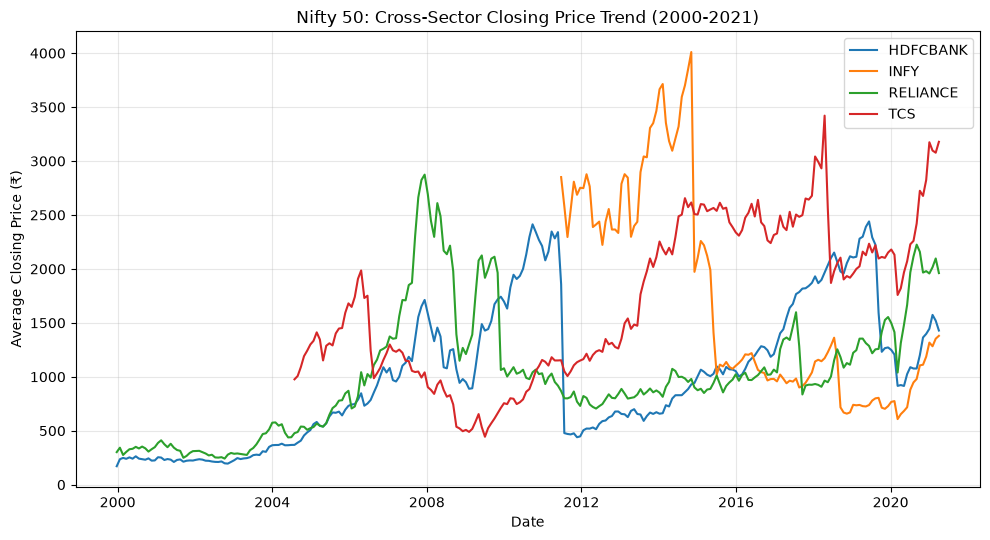

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.5))

for symbol in trend_data["Symbol"].unique():
    subset = trend_data[trend_data["Symbol"] == symbol]
    ax.plot(subset["Date"], subset["avg_Close"], label=symbol)

ax.set_title("Nifty 50: Cross-Sector Closing Price Trend (2000-2021)")
ax.set_ylabel("Average Closing Price (₹)")
ax.set_xlabel("Date")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# Step 1 — Calculate daily price changes

# Stocks selected for trend analysis
stocks = ["RELIANCE", "HDFCBANK", "TCS", "INFY"]

# Filter the four stocks and sort chronologically
stock_data = cleaned_data[
    cleaned_data["Symbol"].isin(stocks)
].copy()

stock_data = stock_data.sort_values(["Symbol", "Date"])

# Calculate daily percentage price change
stock_data["Daily_Change_Pct"] = (
    (stock_data["Close"] / stock_data["Prev Close"]) - 1
) * 100

# Identify unusually large daily declines (15% or more)
large_drops = stock_data[
    stock_data["Daily_Change_Pct"] <= -15
]

# Display relevant information
large_drops[
    ["Date", "Symbol", "Prev Close", "Open", "High",
     "Low", "Close", "Daily_Change_Pct"]
].sort_values("Daily_Change_Pct")

,Date,Symbol,Prev Close,Open,High,Low,Close,Daily_Change_Pct
83246,2011-07-14 00:00:00+00:00,HDFCBANK,2519.7,505.1,513.3,498.8,505.95,-79.920229
168725,2009-11-26 00:00:00+00:00,RELIANCE,2194.7,1111.0,1111.0,1053.3,1063.75,-51.530961
198252,2006-07-28 00:00:00+00:00,TCS,1899.7,940.1,974.95,924.0,928.45,-51.126494
115599,2014-12-02 00:00:00+00:00,INFY,4349.85,2164.95,2164.95,2115.0,2126.6,-51.110958
201186,2018-05-31 00:00:00+00:00,TCS,3514.1,1734.0,1759.05,1726.1,1741.05,-50.455309
170657,2017-09-07 00:00:00+00:00,RELIANCE,1645.4,823.0,832.5,815.0,818.1,-50.279567
198961,2009-06-16 00:00:00+00:00,TCS,778.0,383.3,393.5,371.2,389.15,-49.98072
115731,2015-06-15 00:00:00+00:00,INFY,1975.05,976.95,998.8,968.0,990.45,-49.851902
85270,2019-09-19 00:00:00+00:00,HDFCBANK,2187.75,1099.9,1107.05,1084.0,1101.05,-49.672037
116531,2018-09-04 00:00:00+00:00,INFY,1434.25,722.0,748.5,716.0,737.15,-48.6038


Historical stock prices contain significant discontinuities, several of which appear consistent with corporate actions. Therefore, raw closing prices may not accurately represent historical investment performance.

In [8]:
# Identify potential corporate-action-related price drops

corporate_action_candidates = stock_data[
    stock_data["Daily_Change_Pct"].between(-85, -45)
].copy()

corporate_action_candidates[
    ["Date", "Symbol", "Prev Close", "Open",
     "High", "Low", "Close", "Volume", "Daily_Change_Pct"]
].sort_values(["Symbol", "Date"])

,Date,Symbol,Prev Close,Open,High,Low,Close,Volume,Daily_Change_Pct
83246,2011-07-14 00:00:00+00:00,HDFCBANK,2519.7,505.1,513.3,498.8,505.95,2338586,-79.920229
85270,2019-09-19 00:00:00+00:00,HDFCBANK,2187.75,1099.9,1107.05,1084.0,1101.05,5311655,-49.672037
115599,2014-12-02 00:00:00+00:00,INFY,4349.85,2164.95,2164.95,2115.0,2126.6,2663748,-51.110958
115731,2015-06-15 00:00:00+00:00,INFY,1975.05,976.95,998.8,968.0,990.45,2618213,-49.851902
116531,2018-09-04 00:00:00+00:00,INFY,1434.25,722.0,748.5,716.0,737.15,15370124,-48.6038
168725,2009-11-26 00:00:00+00:00,RELIANCE,2194.7,1111.0,1111.0,1053.3,1063.75,5079362,-51.530961
170657,2017-09-07 00:00:00+00:00,RELIANCE,1645.4,823.0,832.5,815.0,818.1,7408536,-50.279567
198252,2006-07-28 00:00:00+00:00,TCS,1899.7,940.1,974.95,924.0,928.45,754902,-51.126494
198961,2009-06-16 00:00:00+00:00,TCS,778.0,383.3,393.5,371.2,389.15,2172003,-49.98072
201186,2018-05-31 00:00:00+00:00,TCS,3514.1,1734.0,1759.05,1726.1,1741.05,5049371,-50.455309


------------------------------------------------------------------------------------------------------------------------------------------------
### Objective
During the historical trend analysis, several unusually sharp declines in stock prices were observed. The objective was to investigate whether these movements represented genuine market losses or were caused by corporate actions such as stock splits and bonus issues.

### Methodology
- Daily percentage price changes were calculated for RELIANCE, HDFCBANK, TCS and INFY using:
- Daily Change (%) = ((Current Close / Previous Close) - 1) × 100
- A threshold of -15% was used to identify unusually large daily price declines.

The identified records were then filtered further to isolate declines between -45% and -85%. These observations were investigated against historical corporate-action records.

#### Key Findings
1. Several approximately 50% price declines were identified across the selected companies.
2. HDFC Bank experienced an approximately 80% decline on 14 July 2011, corresponding to its 1:5 stock split.
3. Multiple price declines in Infosys and Reliance corresponded to historical 1:1 bonus issues.
4. Three TCS observations showed approximately 50% declines, but their dataset dates did not match the initially identified official corporate-action dates. Further investigation is required.
------------------------------------------------------------------------------------------------------------------------------------------------------

## 2. **Volatility Analysis**
Measure how much each stock's daily price changes fluctuate over time. Higher volatility generally indicates greater price uncertainty and risk.

In [9]:
# Step 1 — Calculate daily returns
stocks = ["RELIANCE", "HDFCBANK", "TCS", "INFY"]

volatility_data = cleaned_data[
    cleaned_data["Symbol"].isin(stocks)
].copy()

volatility_data = volatility_data.sort_values(
    ["Symbol", "Date"]
)

volatility_data["Daily_Return_Pct"] = (
    (volatility_data["Close"] / volatility_data["Prev Close"]) - 1
) * 100

# Step 2 — Check the daily returns
volatility_data[
    ["Date", "Symbol", "Close", "Prev Close", "Daily_Return_Pct"]
].describe()

,Close,Prev Close,Daily_Return_Pct
count,17187.0,17187.0,17187.0
mean,1273.402656,1273.187898,0.063963
std,772.019707,772.072052,2.41595
min,163.4,157.4,-79.920229
25%,730.1,730.025,-0.920373
50%,1074.05,1074.0,0.047616
75%,1838.1,1837.575,1.058646
max,4365.9,4365.9,25.817402


The combined dataset has an average daily return of 0.064% and a standard deviation of 2.416%. However, the unusually large price movements may distort the volatility estimate.

In [10]:
volatility_data.groupby("Symbol")["Daily_Return_Pct"].describe()

,count,mean,std,min,25%,50%,75%,max
Symbol,,,,,,,,
HDFCBANK,5306.0,0.080449,2.39917,-79.920229,-0.860021,0.028494,0.983664,25.817402
INFY,2436.0,0.009511,2.521295,-51.110958,-0.763478,0.064911,0.970025,16.785084
RELIANCE,5306.0,0.072221,2.40563,-51.530961,-1.060585,0.056236,1.189866,21.369252
TCS,4139.0,0.064291,2.387503,-51.126494,-0.892234,0.047497,1.070885,16.229412


- INFY has the highest Standard Deviation(2.521%), i.e. highest daily return volatility among the four stocks.
- TCS has the lowest standard deviation (2.388%), i.e lesser daily return volatility comapred to other stocks. 

In [11]:
# Step3: Identifying largest daily movements for each stock.
volatility_data[
    volatility_data["Daily_Return_Pct"].abs() > 15
][
    ["Date", "Symbol", "Prev Close", "Close", "Daily_Return_Pct"]
].sort_values("Daily_Return_Pct")

,Date,Symbol,Prev Close,Close,Daily_Return_Pct
83246,2011-07-14 00:00:00+00:00,HDFCBANK,2519.7,505.95,-79.920229
168725,2009-11-26 00:00:00+00:00,RELIANCE,2194.7,1063.75,-51.530961
198252,2006-07-28 00:00:00+00:00,TCS,1899.7,928.45,-51.126494
115599,2014-12-02 00:00:00+00:00,INFY,4349.85,2126.6,-51.110958
201186,2018-05-31 00:00:00+00:00,TCS,3514.1,1741.05,-50.455309
170657,2017-09-07 00:00:00+00:00,RELIANCE,1645.4,818.1,-50.279567
198961,2009-06-16 00:00:00+00:00,TCS,778.0,389.15,-49.98072
115731,2015-06-15 00:00:00+00:00,INFY,1975.05,990.45,-49.851902
85270,2019-09-19 00:00:00+00:00,HDFCBANK,2187.75,1101.05,-49.672037
116531,2018-09-04 00:00:00+00:00,INFY,1434.25,737.15,-48.6038


In [12]:
# # Exclude the 10 previously identified extreme negative returns (approximately -50% to -80%) associated with suspected corporate actions to reduce their distortion of volatility estimates.
volatility_filtered = volatility_data[
    ~(
        (volatility_data["Daily_Return_Pct"] <= -45) &
        (volatility_data["Daily_Return_Pct"] >= -85)
    )
].copy()

volatility_filtered.groupby("Symbol")["Daily_Return_Pct"].std()

Symbol
HDFCBANK    2.020873
INFY        1.814507
RELIANCE     2.19286
TCS         1.961202
Name: Daily_Return_Pct, dtype: Float64

- After excluding 10 extreme negative-return observations associated with suspected corporate actions, RELIANCE recorded the highest volatility (2.19%),
while INFY recorded the lowest (1.81%). This indicates that the identified price discontinuities had a noticeable impact on the initial volatility estimates.

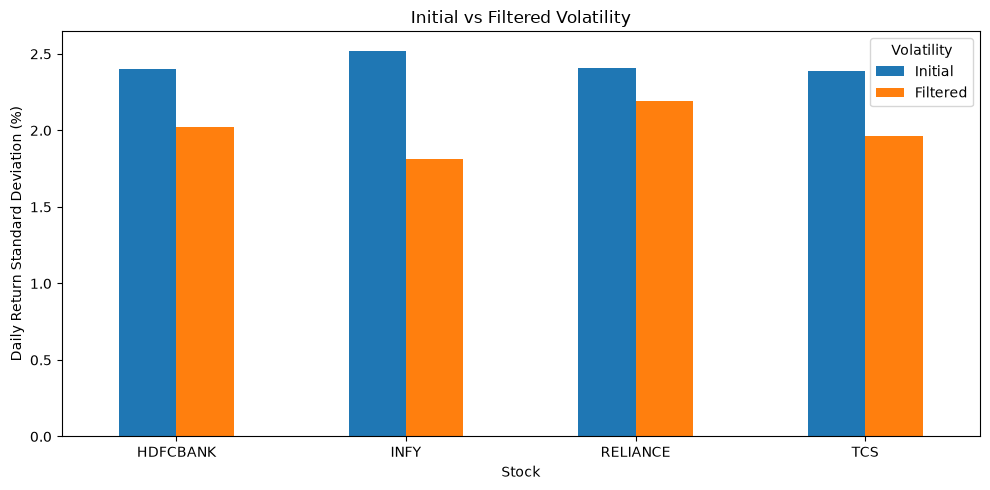

In [13]:
initial_volatility = volatility_data.groupby("Symbol")["Daily_Return_Pct"].std()
filtered_volatility = volatility_filtered.groupby("Symbol")["Daily_Return_Pct"].std()

volatility_comparison = pd.DataFrame({
    "Initial": initial_volatility,
    "Filtered": filtered_volatility
})

volatility_comparison.plot(kind="bar", figsize=(10, 5))

plt.title("Initial vs Filtered Volatility")
plt.xlabel("Stock")
plt.ylabel("Daily Return Standard Deviation (%)")
plt.xticks(rotation=0)
plt.legend(title="Volatility")
plt.tight_layout()
plt.show()

-----------------------------------------------------------------------------------------------------------------------------------------------------------
**Objective**: Compare the daily return volatility of RELIANCE, HDFCBANK, TCS, and INFY using standard deviation.

**Methodology**: Calculated daily percentage returns and compared initial volatility against filtered volatility after excluding 10 extreme negative-return observations associated with suspected corporate actions.

**Key Findings**:
- Initially, INFY recorded the highest volatility (2.52%), while TCS recorded the lowest (2.39%).
- After filtering, RELIANCE recorded the highest volatility (2.19%), while INFY recorded the lowest (1.81%).
- All four stocks showed a reduction in volatility after filtering.
- The comparison demonstrates how extreme price movements can significantly influence volatility measurements.
-----------------------------------------------------------------------------------------------------------------------------------------------------------

## 3. **Correlation Analysis**
Correlation Analysis of Selected Nifty 50 Stocks (2000–2021)

In [14]:
correlation_data = volatility_filtered.pivot(
    index="Date",
    columns="Symbol",
    values="Daily_Return_Pct"
)

correlation_data.head()

Symbol,HDFCBANK,INFY,RELIANCE,TCS
Date,,,,
2000-01-03 00:00:00+00:00,8.005083,<NA>,8.002575,<NA>
2000-01-04 00:00:00+00:00,2.235294,<NA>,8.005562,<NA>
2000-01-05 00:00:00+00:00,-3.941312,<NA>,3.917602,<NA>
2000-01-06 00:00:00+00:00,0.808625,<NA>,4.19469,<NA>
2000-01-07 00:00:00+00:00,0.029709,<NA>,6.862579,<NA>


In [15]:
print(correlation_data.shape)
print(correlation_data.isna().sum())

(5306, 4)
Symbol
HDFCBANK       2
INFY        2873
RELIANCE       2
TCS         1170
dtype: int64


In [16]:
correlation_matrix = correlation_data.corr()
correlation_matrix

Symbol,HDFCBANK,INFY,RELIANCE,TCS
Symbol,,,,
HDFCBANK,1.000000,0.226427,0.402345,0.341392
INFY,0.226427,1.000000,0.219107,0.510135
RELIANCE,0.402345,0.219107,1.000000,0.380269
TCS,0.341392,0.510135,0.380269,1.000000


- INFY and TCS has strongest relationship, their correlation is approximately 0.51.

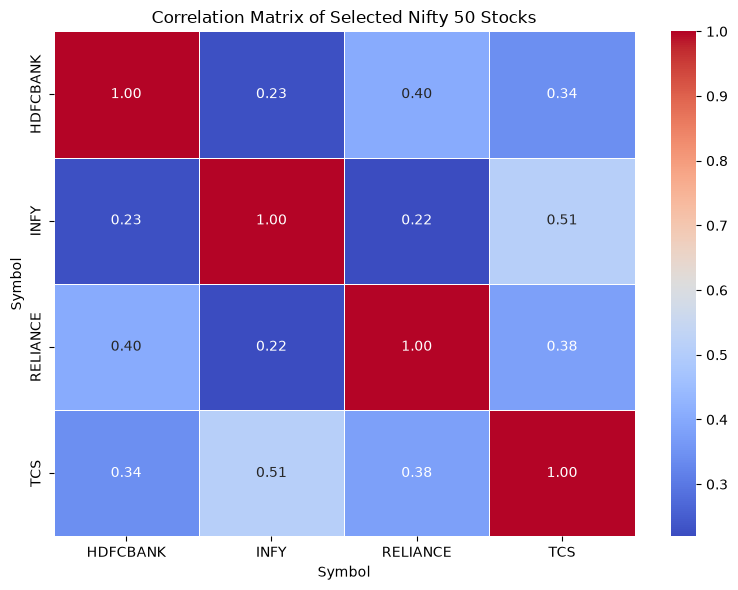

In [17]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Selected Nifty 50 Stocks")
plt.tight_layout()
plt.show()

-----------------------------------------------------------------------------------------------------------------------------------------------------------
**Objective**
Understand how the daily returns of RELIANCE, HDFCBANK, TCS and INFY move in relation to each other.

**Methodology**

- Used daily percentage returns instead of closing prices.
- Aligned stock returns by date using a pivot operation.
- Excluded the 10 previously identified extreme negative observations.
- Calculated Pearson correlation coefficients between stock pairs.
- Visualized the correlation matrix using a heatmap.

**Key Insights**

- INFY and TCS had the strongest positive correlation (0.51). Both belong to the IT sector.
- INFY and RELIANCE had the weakest correlation (0.22).
- All six stock pairs showed positive correlations, indicating some common movement.
- None showed a very strong correlation close to +1.
- Correlation indicates association, not causation.
-----------------------------------------------------------------------------------------------------------------------------------------------------------

## 4. **Trading Activity Analysis**
Analyse the trading activity of RELIANCE, HDFCBANK, TCS and INFY using daily trading volume and turnover

In [18]:
stocks = ["RELIANCE", "HDFCBANK", "TCS", "INFY"]

trading_data = cleaned_data[
    cleaned_data["Symbol"].isin(stocks)
].copy()

trading_data.head(2)

,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,_Deliverble,Turnover_corrected
80365,2000-01-03 00:00:00+00:00,HDFCBANK,EQ,157.4,166.0,170.0,166.0,170.0,170.0,169.52,33259,563812250000.0,<NA>,<NA>,<NA>,5638122.5
80366,2000-01-04 00:00:00+00:00,HDFCBANK,EQ,170.0,182.0,183.45,171.0,174.0,173.8,174.99,168710,2952261350000.0,<NA>,<NA>,<NA>,29522613.5


In [19]:
# Calculate Average Daily Trading Activity
trading_summary = (
    trading_data.groupby("Symbol")
    .agg(
        Average_Daily_Volume=("Volume", "mean"),
        Average_Daily_Turnover=("Turnover_corrected", "mean")
    )
    .round(2)
)

trading_summary

,Average_Daily_Volume,Average_Daily_Turnover
Symbol,,
HDFCBANK,2102579.52,2448836674.48
INFY,4498398.84,5147947832.75
RELIANCE,5583027.54,6076714582.6
TCS,1676761.95,2952102050.12


RELIANCE has the highest average daily volume and turnover among the four stocks.

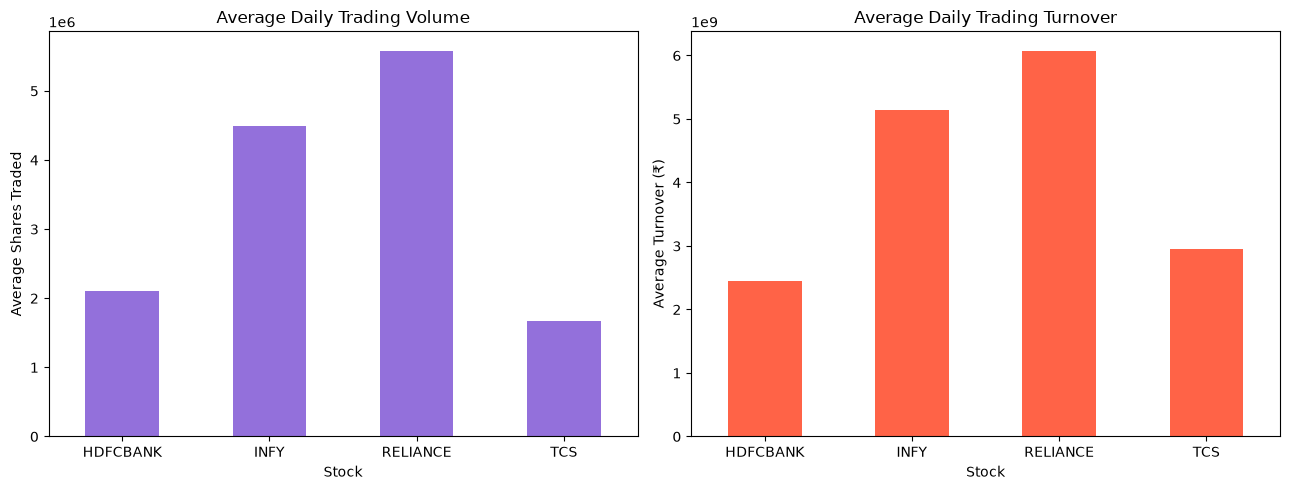

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: Average Daily Volume
trading_summary["Average_Daily_Volume"].plot(
    kind="bar",
    ax=axes[0],
    color="mediumpurple"
)

axes[0].set_title("Average Daily Trading Volume")
axes[0].set_xlabel("Stock")
axes[0].set_ylabel("Average Shares Traded")
axes[0].tick_params(axis="x", rotation=0)

# Chart 2: Average Daily Turnover
trading_summary["Average_Daily_Turnover"].plot(
    kind="bar",
    ax=axes[1],
    color="tomato"
)

axes[1].set_title("Average Daily Trading Turnover")
axes[1].set_xlabel("Stock")
axes[1].set_ylabel("Average Turnover (₹)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

--------------------------------------------------------------------------------------------------------------------------------------
**Objective**:  Compare the average daily trading volume and turnover of RELIANCE, HDFCBANK, TCS and INFY to understand their trading activity.

**Methodology**

- Selected the four stocks from the cleaned dataset.
- Calculated average daily trading volume for each stock.
- Calculated average daily turnover using the corrected turnover values.
- Compared both metrics using bar charts.

**Key Insights**

- RELIANCE recorded the highest average daily volume (5.58 million shares) and turnover (approximately ₹60.77 crore).
- INFY ranked second in both measures.
- TCS had lower average daily volume than HDFCBANK but higher turnover.
- Higher trading volume does not necessarily mean higher monetary trading activity because share prices differ.
- Turnover provides a better measure of the monetary value of trading activity.
-------------------------------------------------------------------------------------------------------------------------------------

## 5. **Drawdown & Rolling Risk Analysis**
Evaluate the historical downside risk and changing volatility of RELIANCE, HDFCBANK, TCS and INFY.

In [21]:
drawdown_data = volatility_filtered.copy()

drawdown_data = drawdown_data.sort_values(
    ["Symbol", "Date"]
)

drawdown_data["Daily_Return"] = (
    drawdown_data["Daily_Return_Pct"] / 100
)

drawdown_data["Cumulative_Return"] = (
    drawdown_data.groupby("Symbol")["Daily_Return"]
    .transform(lambda x: (1 + x).cumprod())
)

drawdown_data.head()

,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,_Deliverble,Turnover_corrected,Daily_Return_Pct,Daily_Return,Cumulative_Return
80365,2000-01-03 00:00:00+00:00,HDFCBANK,EQ,157.4,166.0,170.0,166.0,170.0,170.0,169.52,33259,563812250000.0,<NA>,<NA>,<NA>,5638122.5,8.005083,0.080051,1.080051
80366,2000-01-04 00:00:00+00:00,HDFCBANK,EQ,170.0,182.0,183.45,171.0,174.0,173.8,174.99,168710,2952261350000.0,<NA>,<NA>,<NA>,29522613.5,2.235294,0.022353,1.104193
80367,2000-01-05 00:00:00+00:00,HDFCBANK,EQ,173.8,170.0,173.9,165.0,168.0,166.95,169.2,159820,2704093975000.0,<NA>,<NA>,<NA>,27040939.75,-3.941312,-0.039413,1.060673
80368,2000-01-06 00:00:00+00:00,HDFCBANK,EQ,166.95,168.0,170.0,165.3,168.95,168.3,168.44,85026,1432165990000.0,<NA>,<NA>,<NA>,14321659.9,0.808625,0.008086,1.06925
80369,2000-01-07 00:00:00+00:00,HDFCBANK,EQ,168.3,162.15,171.0,162.15,170.75,168.35,166.79,85144,1420157785000.0,<NA>,<NA>,<NA>,14201577.85,0.029709,0.000297,1.069568


In [ ]:
anomaly_data = volatility_filtered.copy()

anomaly_data = anomaly_data.cort_values(
    ["Symbol", "Date"]
)

In [24]:
import numpy as np
anomaly_data["Log_Volume"] = np.log1p(
    anomaly_data["Volume"]
)

anomaly_data["Rolling_Mean_Volume"] = (
    anomaly_data.groupby("Symbol")["Log_Volume"]
    .transform(
        lambda x: x.shift(1).rolling(20).mean()
    )
)

anomaly_data["Rolling_Std_Volume"] = (
    anomaly_data.groupby("Symbol")["Log_Volume"]
    .transform(
        lambda x: x.shift(1).rolling(20).std()
    )
)

anomaly_data["Volume_ZScore"] = (
    (anomaly_data["Log_Volume"] -
     anomaly_data["Rolling_Mean_Volume"]) /
    anomaly_data["Rolling_Std_Volume"]
)

In [25]:
anomaly_data["Significant_Price_Movement"] = (
    anomaly_data["Daily_Return_Pct"].abs() >= 3
)

In [26]:
anomaly_data["Unusual_Trading_Activity"] = (
    (anomaly_data["Volume_ZScore"] >= 2) &
    (anomaly_data["Significant_Price_Movement"])
)

In [27]:
unusual_activity = anomaly_data[
    anomaly_data["Unusual_Trading_Activity"]
].copy()

unusual_activity[[
    "Date",
    "Symbol",
    "Close",
    "Volume",
    "Daily_Return_Pct",
    "Volume_ZScore"
]].sort_values(
    "Volume_ZScore",
    ascending=False
)

,Date,Symbol,Close,Volume,Daily_Return_Pct,Volume_ZScore
201132,2018-03-13 00:00:00+00:00,TCS,2886.8,44033577,-5.417493,14.14173
84633,2017-02-17 00:00:00+00:00,HDFCBANK,1377.05,100564990,3.701333,8.349107
116000,2016-07-15 00:00:00+00:00,INFY,1072.55,30742063,-8.816153,8.109842
114946,2012-04-13 00:00:00+00:00,INFY,2402.55,9406946,-12.655191,7.903223
84950,2018-05-31 00:00:00+00:00,HDFCBANK,2139.45,9909798,4.447482,7.870866
...,...,...,...,...,...,...
168456,2008-10-16 00:00:00+00:00,RELIANCE,1391.95,10250021,-8.43639,2.023762
166545,2001-03-01 00:00:00+00:00,RELIANCE,438.2,15937433,5.81985,2.022253
200189,2014-05-19 00:00:00+00:00,TCS,2036.7,3258303,-5.741062,2.011708
201456,2019-07-05 00:00:00+00:00,TCS,2163.1,4088470,-3.547143,2.004617


In [28]:
anomaly_summary = (
    unusual_activity.groupby("Symbol")
    .size()
    .reset_index(name="Unusual_Activity_Count")
    .sort_values(
        "Unusual_Activity_Count",
        ascending=False
    )
)

anomaly_summary

,Symbol,Unusual_Activity_Count
2,RELIANCE,105
3,TCS,73
0,HDFCBANK,72
1,INFY,51
